In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

In [4]:
dataset = load_dataset("badrex/nnti-dataset-full")

Generating validation split: 100%|██████████| 3300/3300 [00:00<00:00, 15011.73 examples/s]


In [24]:
df = dataset['train'].to_pandas()

In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8689 entries, 0 to 8688
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   audio_filepath  8689 non-null   object 
 1   duration        8689 non-null   float64
 2   speaker_id      8689 non-null   str    
 3   scenario        8689 non-null   str    
 4   age_group       8689 non-null   str    
 5   job_type        8689 non-null   str    
 6   area            8689 non-null   str    
 7   language        8689 non-null   str    
dtypes: float64(1), object(1), str(6)
memory usage: 997.3+ KB


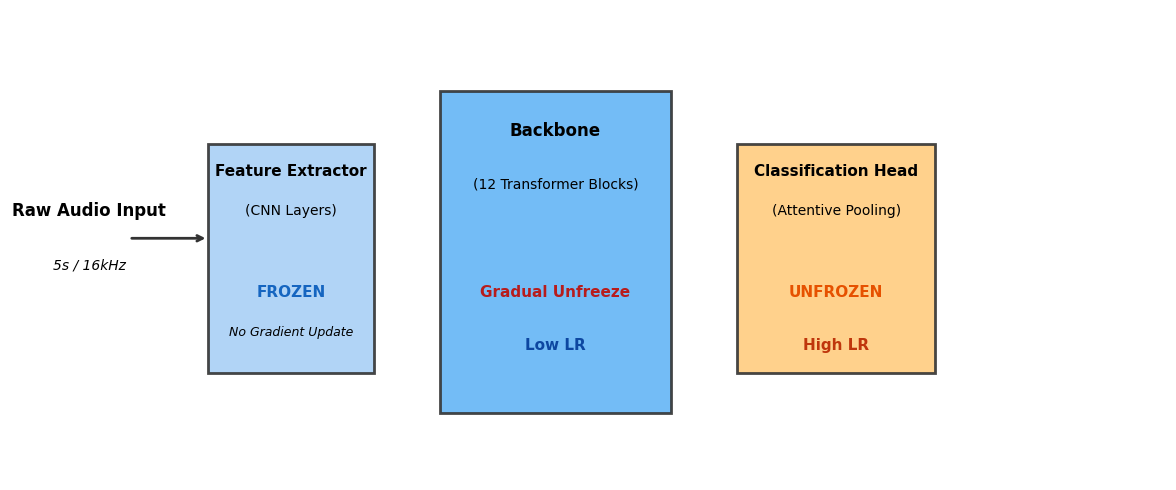

In [23]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Initialize the figure
fig, ax = plt.subplots(figsize=(12, 5))

# Define common styles
arrow_props = dict(arrowstyle='->', lw=2, color='#333333')
box_edge_color = '#333333'

# 1. Input Node
ax.text(-1.8, 2.0, 'Raw Audio Input', ha='center', va='center', fontweight='bold', fontsize=12)
ax.text(-1.8, 1.6, '5s / 16kHz', ha='center', va='center', fontsize=10, style='italic')
ax.annotate('', xy=(0, 1.8), xytext=(-1.2, 1.8), arrowprops=arrow_props)

# 2. Feature Extractor (CNN) - FROZEN
cnn_box = patches.Rectangle((0, 0.8), 2.5, 1.7, linewidth=2, edgecolor=box_edge_color, facecolor='#A9D0F5', alpha=0.9)
ax.add_patch(cnn_box)
ax.text(1.25, 2.3, 'Feature Extractor', ha='center', va='center', fontweight='bold', fontsize=11)
ax.text(1.25, 2.0, '(CNN Layers)', ha='center', va='center', fontsize=10)
ax.text(1.25, 1.4, 'FROZEN', ha='center', va='center', fontsize=11, fontweight='bold', color='#1565C0')
ax.text(1.25, 1.1, 'No Gradient Update', ha='center', va='center', fontsize=9, style='italic')

# 3. Backbone (Transformer) - GRADUAL UNFREEZE
backbone_box = patches.Rectangle((3.5, 0.5), 3.5, 2.4, linewidth=2, edgecolor=box_edge_color, facecolor='#64B5F6', alpha=0.9)
ax.add_patch(backbone_box)
ax.text(5.25, 2.6, 'Backbone', ha='center', va='center', fontweight='bold', fontsize=12)
ax.text(5.25, 2.2, '(12 Transformer Blocks)', ha='center', va='center', fontsize=10)
ax.text(5.25, 1.4, 'Gradual Unfreeze', ha='center', va='center', fontsize=11, fontweight='bold', color='#B71C1C')
ax.text(5.25, 1.0, r'Low LR', ha='center', va='center', fontsize=11, fontweight='bold', color='#0D47A1')

# 4. Classification Head - UNFROZEN
head_box = patches.Rectangle((8, 0.8), 3, 1.7, linewidth=2, edgecolor=box_edge_color, facecolor='#FFCC80', alpha=0.9)
ax.add_patch(head_box)
ax.text(9.5, 2.3, 'Classification Head', ha='center', va='center', fontweight='bold', fontsize=11)
ax.text(9.5, 2.0, '(Attentive Pooling)', ha='center', va='center', fontsize=10)
ax.text(9.5, 1.4, 'UNFROZEN', ha='center', va='center', fontsize=11, fontweight='bold', color='#E65100')
ax.text(9.5, 1.0, r'High LR', ha='center', va='center', fontsize=11, fontweight='bold', color='#BF360C')

# Formatting and Saving
ax.set_xlim(-3, 14.5)
ax.set_ylim(0, 3.5)
ax.axis('off')
plt.tight_layout()
plt.savefig('detailed_architecture.png', dpi=300, bbox_inches='tight')

In [ ]:
sweep_config = {
    'method': 'bayes',
    'metric': {'name': 'eval/accuracy', 'goal': 'maximize'},
    'parameters': {
        'batch_size':        {'values': [16, 32]},
        'weight_decay':      {'min': 0.0,  'max': 0.1},
        'warmup_ratio':      {'min': 0.0,  'max': 0.2},
        'backbone_lr':       {'distribution': 'log_uniform_values', 'min': 1e-6, 'max': 5e-5},
        'head_lr':           {'distribution': 'log_uniform_values', 'min': 1e-4, 'max': 5e-3},
        'unfreeze_at_step':  {'values': [100, 200, 500]},
        'label_smoothing':   {'distribution': 'uniform', 'min': 0.0, 'max': 0.2},
        'hidden_dropout':    {'values': [0.0, 0.1, 0.2]},
    }
}

/var/folders/s0/w4f6ly4d4sj0k7dbwrpb48w40000gn/T/ipykernel_37168/3579086255.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object', 'category']).columns


TypeError: unhashable type: 'dict'

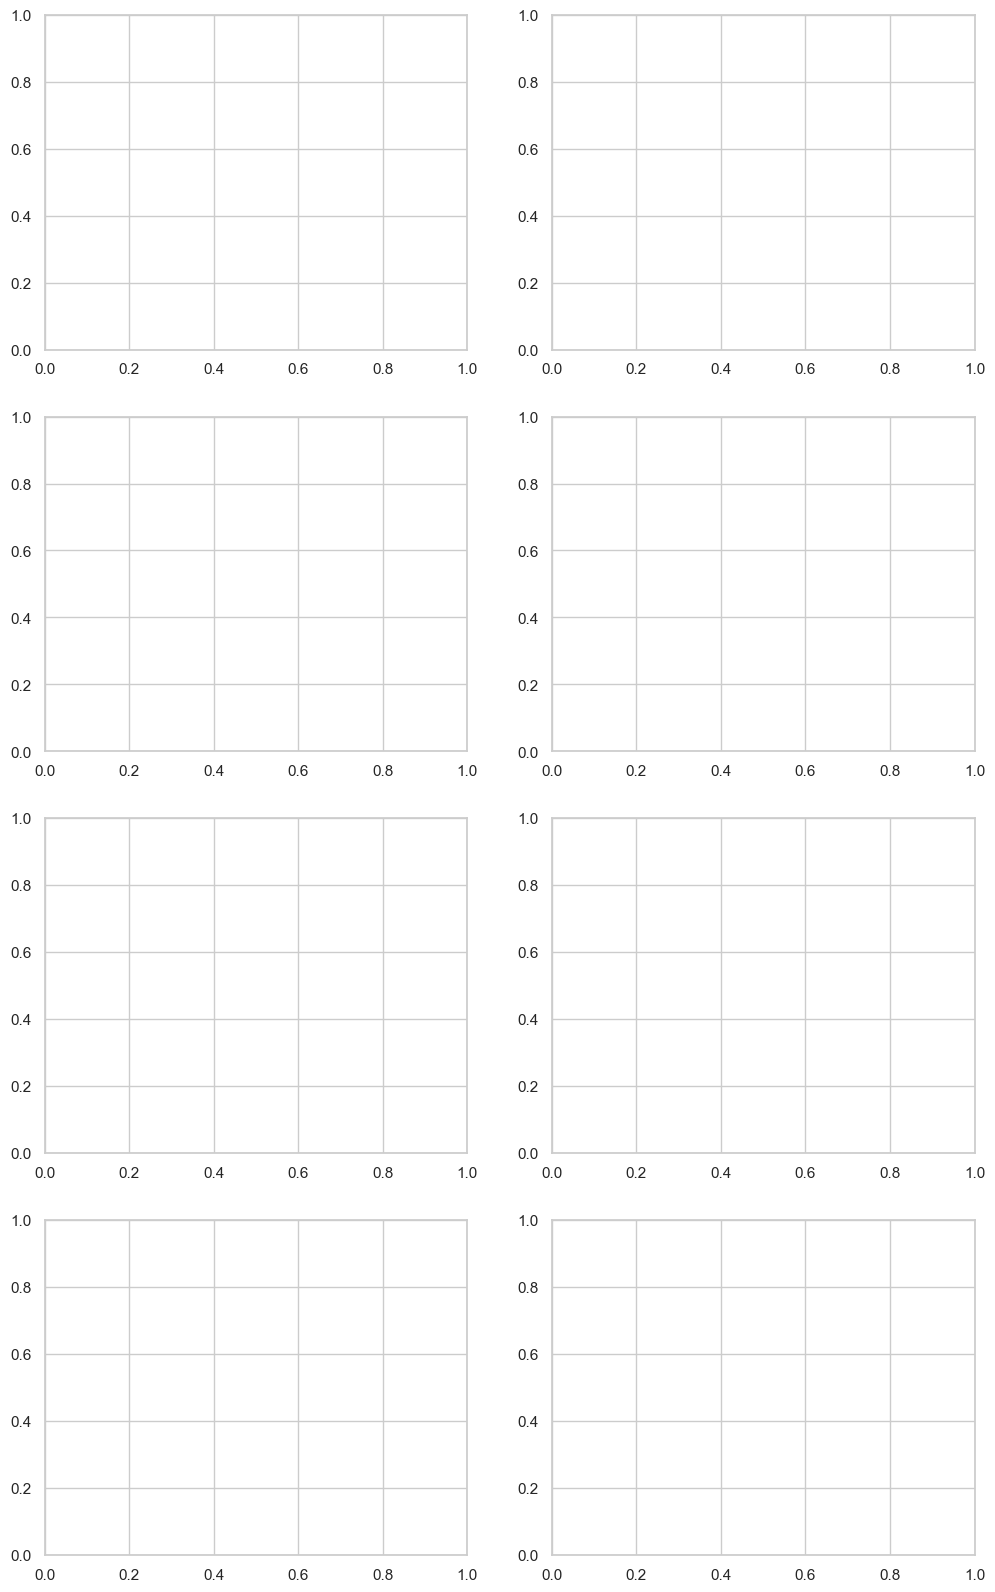

In [28]:
sns.set_theme(style="whitegrid")

def plot_dataset_summary(df):
    # Identify column types
    num_cols = df.select_dtypes(include=['number']).columns
    cat_cols = df.select_dtypes(include=['object', 'category']).columns

    # Calculate grid size (one plot per column)
    total_plots = len(num_cols) + len(cat_cols)
    fig, axes = plt.subplots(nrows=(total_plots // 2) + (total_plots % 2),
                             ncols=2, figsize=(12, 5 * (total_plots // 2)))
    axes = axes.flatten()

    for i, col in enumerate(df.columns):
        if col in num_cols:
            # Histogram for numeric data
            sns.histplot(df[col], kde=True, ax=axes[i], color='skyblue')
            axes[i].set_title(f'Distribution of {col}')
        else:
            # Countplot for categorical data
            # (Limiting to top 10 if there are too many categories)
            top_values = df[col].value_counts().nlargest(10)
            sns.barplot(x=top_values.values, y=top_values.index, ax=axes[i], palette='viridis')
            axes[i].set_title(f'Top Values in {col}')

    # Remove any empty subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

# Run the visualization
plot_dataset_summary(df)